## <center>Assignment 2</center>

### <center>Part 2: Hunga Tonga Analysis</center>

#### Name: Shreyas Dhumal
#### Student no: 26106049

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from matplotlib.colors import rgb_to_hsv
from matplotlib.colors import ListedColormap
import rasterio
from rasterio.plot import show
import pathlib
%matplotlib widget

In [2]:
def load_white_light_images(path):
    """
    Load Google Earth JPG images and extract dates
    """
    here = pathlib.Path('.')
    folder = here / path
    filelist = sorted(folder.glob("*.JPG"))


    white_images = []

    for file in filelist:
        white_data = mpimg.imread(file)
        white_images.append({
            "filename": file.name,
            "path": file,
            "data": white_data
        })

    return white_images

    ""
white_light_images = load_white_light_images('sentinel-processed/White_light')
#print("Number of images:", len(white_light_images))

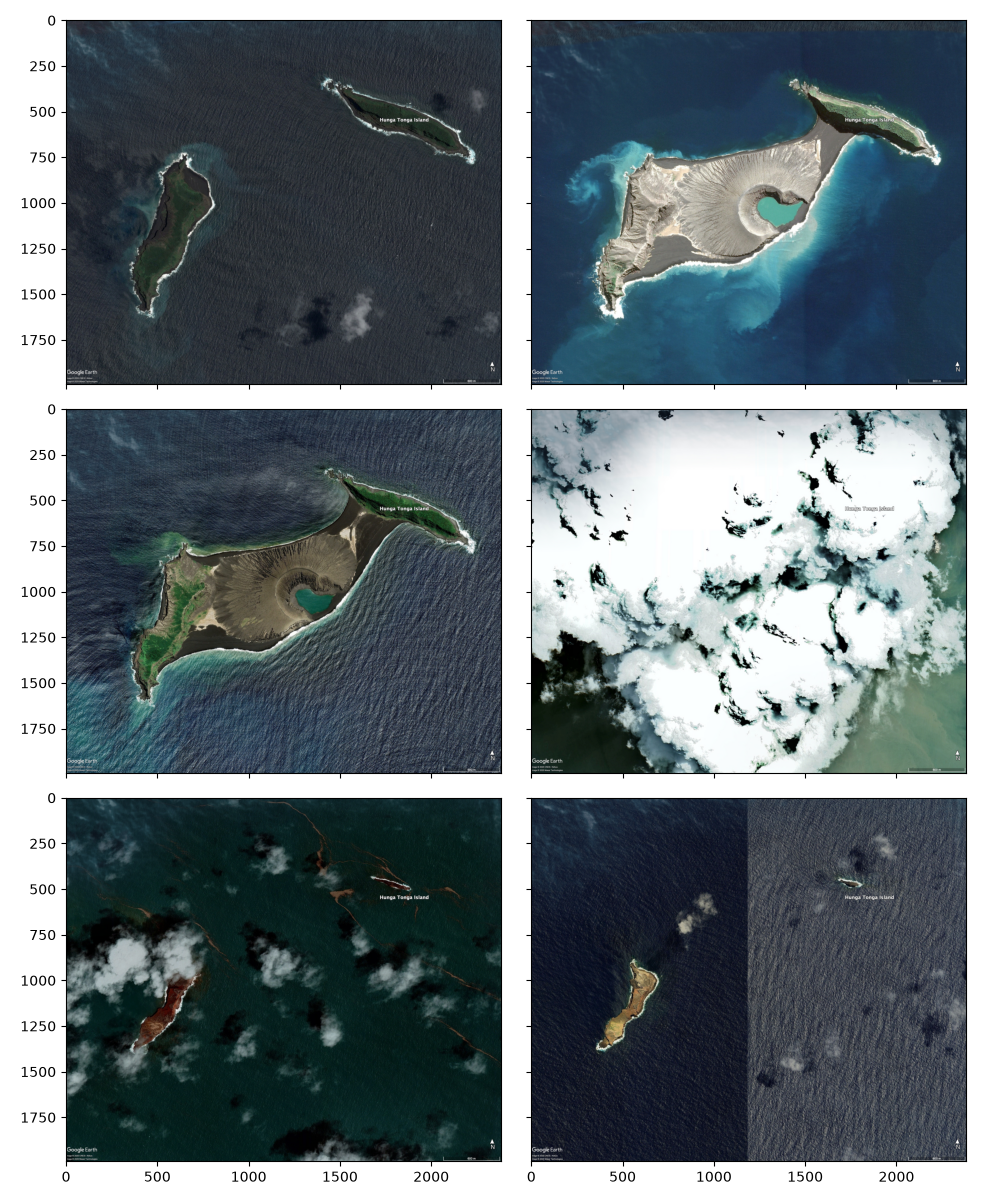

In [3]:
white_image = list(white_light_images)
# for im in white_image:
#     print(im)
plt.close('all')
fig, axes = plt.subplots(nrows=3, ncols=2, figsize=(10, 12), tight_layout=True, sharex=True, sharey=True)
axes = axes.ravel()

for i, ax in enumerate(axes):
    img = white_image[i]["data"]
    ax.imshow(img)

In [4]:
# from cropping the all the images, I got the 600m as scale and line width for 600 m are x axis values, which are same for all images

real_world_distance = 600
start_x = 2067.6
end_x = 2375.1

def calculate_pixel_scale(real_world_m, start_x, end_x):
    """
    Calculate ground distance and area represented by one pixel
    """
    real_world_pixels = end_x - start_x
    metres_per_pixel = real_world_m / real_world_pixels
    area_per_pixel = metres_per_pixel ** 2

    return metres_per_pixel, area_per_pixel


metres_per_pixel, area_per_pixel = calculate_pixel_scale(real_world_distance, start_x, end_x)

print(f"Ground scale: {metres_per_pixel:.2f} m/pixel")
print(f"Area per pixel: {area_per_pixel:.2f} m²/pixel")

Ground scale: 1.95 m/pixel
Area per pixel: 3.81 m²/pixel


### Identifing land area

In [5]:
def get_land_areas(image_paths, pixel_area, threshold=0.45):
    """
    Calculates the land area for a list of white light images
    """
    land_areas = []
    land_masks = []
    
    for white_file in image_paths:
        img_norm = white_file["data"] / 255.0 
        hsv_img = rgb_to_hsv(img_norm)
        
        # mask = hsv_img[:, :, 0] < threshold
        # for clouds 
        water_mask = hsv_img[:, :, 0]
        cloud_mask = hsv_img[:, :, 1]
        mask = (water_mask < 0.45) & (cloud_mask > 0.1)
        
        land_pixels = mask.sum()
        area_m2 = land_pixels * pixel_area
        
        land_areas.append(area_m2)
        land_masks.append(mask)
        
    return land_areas, land_masks
    
land_areas, land_masks = get_land_areas(white_light_images, area_per_pixel)

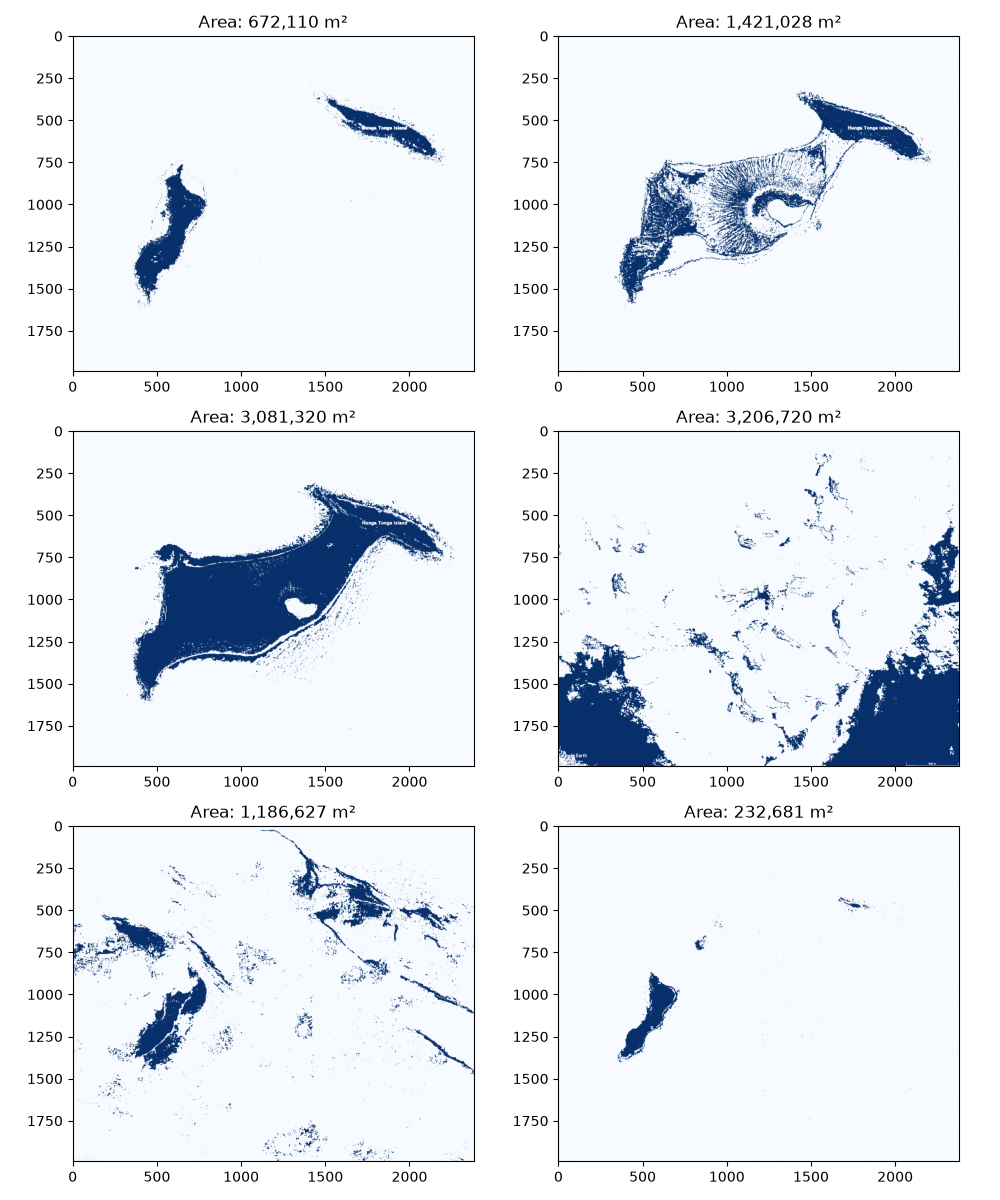

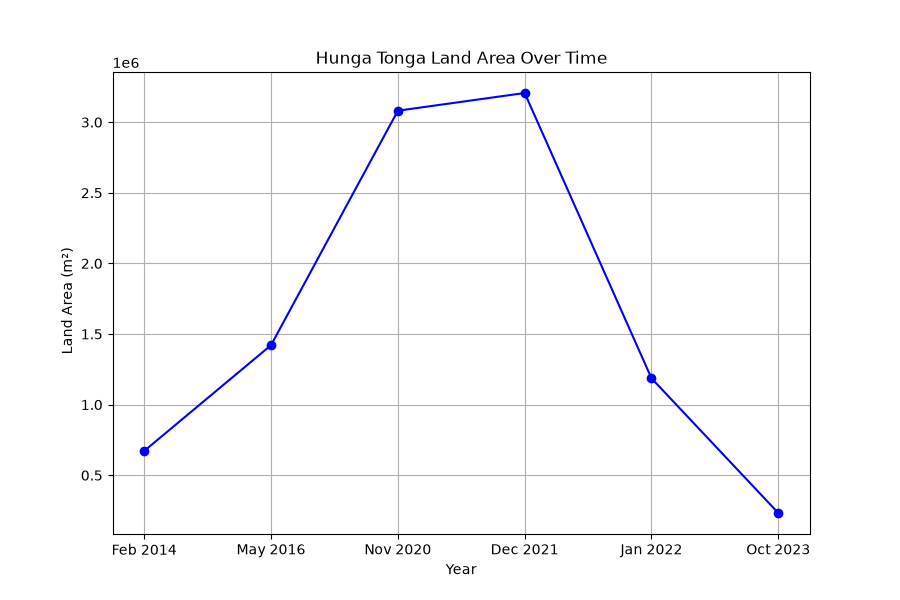

In [6]:
plt.close('all')
fig, axes = plt.subplots(nrows=3, ncols=2, figsize=(10, 12), tight_layout=True)
for i, ax in enumerate(axes.ravel()):
    ax.imshow(land_masks[i], cmap='Blues')
    ax.set_title(f"Area: {land_areas[i]:,.0f} m²")
plt.show()


# Graph for Land Area over time
years = ['Feb 2014', 'May 2016', 'Nov 2020', 'Dec 2021', 'Jan 2022', 'Oct 2023']
plt.figure(figsize=(9, 6))
plt.plot(years, land_areas, marker='o', linestyle='-', color='b')
plt.title('Hunga Tonga Land Area Over Time')
plt.xlabel('Year')
plt.ylabel(' Land Area (m²)')
plt.grid(True)


**Note on December 2021 Land Area Spike:** </br> 
The land area suddenly increases to around 3.21 million m² in December 2021. The clouds may have been incorrectly classified as land because they meet the color threshold used in my code. Thats why, this increase is likely caused by cloud cover rather than actual land expansion before the January 2022 eruption.

### Sentinel-2 Data

In [7]:
def get_sentinel_folders(where, year):
    """
    Tell the function where to look and what year to get the data for
    """
    year = str(year)
    folders = sorted(list(where.glob(f"S2_{year}*")))
    
    return folders

here = pathlib.Path('sentinel-processed')

folders_2017 = get_sentinel_folders(here, 2017)
folders_2018 = get_sentinel_folders(here, 2018)
folders_2019 = get_sentinel_folders(here, 2019)

print("2017:", folders_2017)
print("2018:", folders_2018)
print("2019:", folders_2019)

2017: [WindowsPath('sentinel-processed/S2_2017-07-12')]
2018: [WindowsPath('sentinel-processed/S2_2018-07-12')]
2019: [WindowsPath('sentinel-processed/S2_2019-07-12')]


In [8]:
def load_bands(folders):
    """
    Loops through a list of folders, gets the Red and NIR bands
    """
    all_years_data = []
    
    for folder in folders:
        files = sorted(list(folder.glob("*.tiff")))
       
        with rasterio.open(files[3]) as src_red:    #for band 4 red band
            b4 = src_red.read(1)
            resolution = src_red.res
            bounds = src_red.bounds
            
        with rasterio.open(files[7]) as src_nir:    #for band 8 NIR band
            b8 = src_nir.read(1)
            
        # determining the pixel size 
        # for x meter reference: https://edukatesg.com/2026/10/06/why-mathematics-earth-maps-latitude-longitude-map-projections/
        latitude = bounds.bottom
        y_meters = resolution[1] * 111320                             # spherical Earth approximation 
        x_meters = resolution[0] * 111320 * np.cos(np.radians(latitude))  
        pixel_area = x_meters * y_meters
        
        all_years_data.append({
            "folder_name": folder.name,
            "red": b4,
            "nir": b8,
            "pixel_area": pixel_area
        })
        
    return all_years_data

sentinel_data_2017 = load_bands(folders_2017)
sentinel_data_2018 = load_bands(folders_2018)
sentinel_data_2019 = load_bands(folders_2019)


#### Getting Vegetation Area

In [9]:
def calculate_vegetation(sentinel_data):
    """
    Calculates total vegetation area
    """
    
    combined_vegetation = []
    
    for data in sentinel_data:
        red = data["red"]
        nir = data["nir"]
        
        # NDVI formula: (NIR - Red) / (NIR + Red)
        denominator = (nir + red)
        denominator[denominator == 0] = 0.0001   # to avoid division by zero (gives error for some values)
        ndvi = (nir - red) / denominator

        # Threshold 0.2 to 0.5: Sparse vegetation, grasses, shrubs, or early plant growth.
        # reference: https://science.nasa.gov/earth/earth-observatory/measuring-vegetation-ndvi-evi/
        veg_mask = ndvi > 0.2
        veg_pixels = veg_mask.sum()
        # Convert pixel count to real-world area 
        total_veg_area = veg_pixels * data["pixel_area"]
        
        combined_vegetation.append({
            "date": data["folder_name"],
            "veg_area_m2": total_veg_area,
            "ndvi": ndvi,
            "veg_mask": veg_mask
        })

    return combined_vegetation

#### AI Useage:
I have used Google Gemini for identifing error when dividing (nir + red). Some values are comes out to be 0 so used this code: denominator[denominator == 0] = 0.0001, to solve this error.

In [10]:
# date_2017, veg_areas_2017 = calculate_vegetation(sentinel_data_2017)
# date_2018, veg_areas_2018 = calculate_vegetation(sentinel_data_2018)
# date_2019, veg_areas_2019 = calculate_vegetation(sentinel_data_2019)

combined_vegetation = calculate_vegetation(sentinel_data_2017 + sentinel_data_2018 + sentinel_data_2019)
for item in combined_vegetation:
    print(f"Date: {item['date']} Vegetation Area: {item['veg_area_m2']:.0f} m²")

Date: S2_2017-07-12 Vegetation Area: 686664 m²
Date: S2_2018-07-12 Vegetation Area: 722287 m²
Date: S2_2019-07-12 Vegetation Area: 857145 m²


In [11]:
# for the plot:
dates = []
veg_areas = []

dates = [item["date"] for item in combined_vegetation]
veg_areas = [item["veg_area_m2"] / 1000000 for item in combined_vegetation]

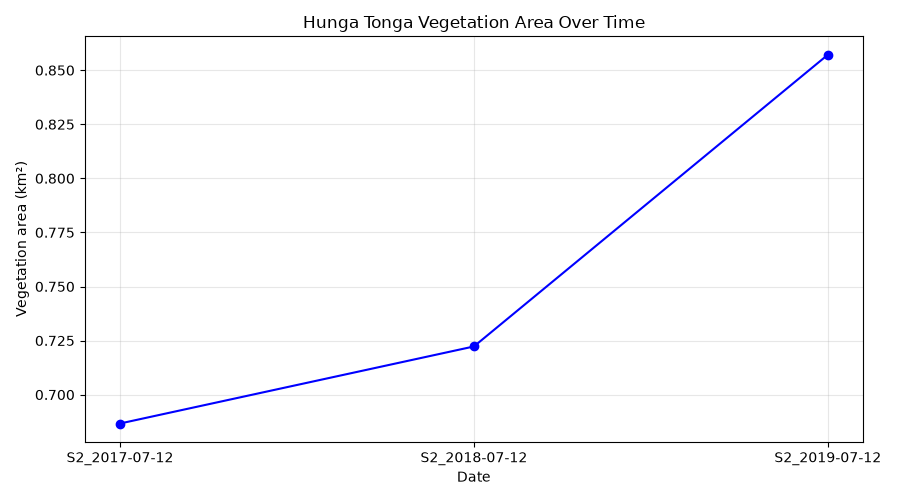

In [12]:
def vegetation_area_plot(dates, veg_areas):

    plt.figure(figsize=(9, 5))

    plt.plot(dates, veg_areas, marker='o', linestyle='-', color='b')

    plt.title("Hunga Tonga Vegetation Area Over Time")
    plt.xlabel("Date")
    plt.ylabel("Vegetation area (km²)")

    plt.grid(True, alpha=0.3)
    plt.tight_layout()

    plt.show()


vegetation_area_plot(dates, veg_areas)

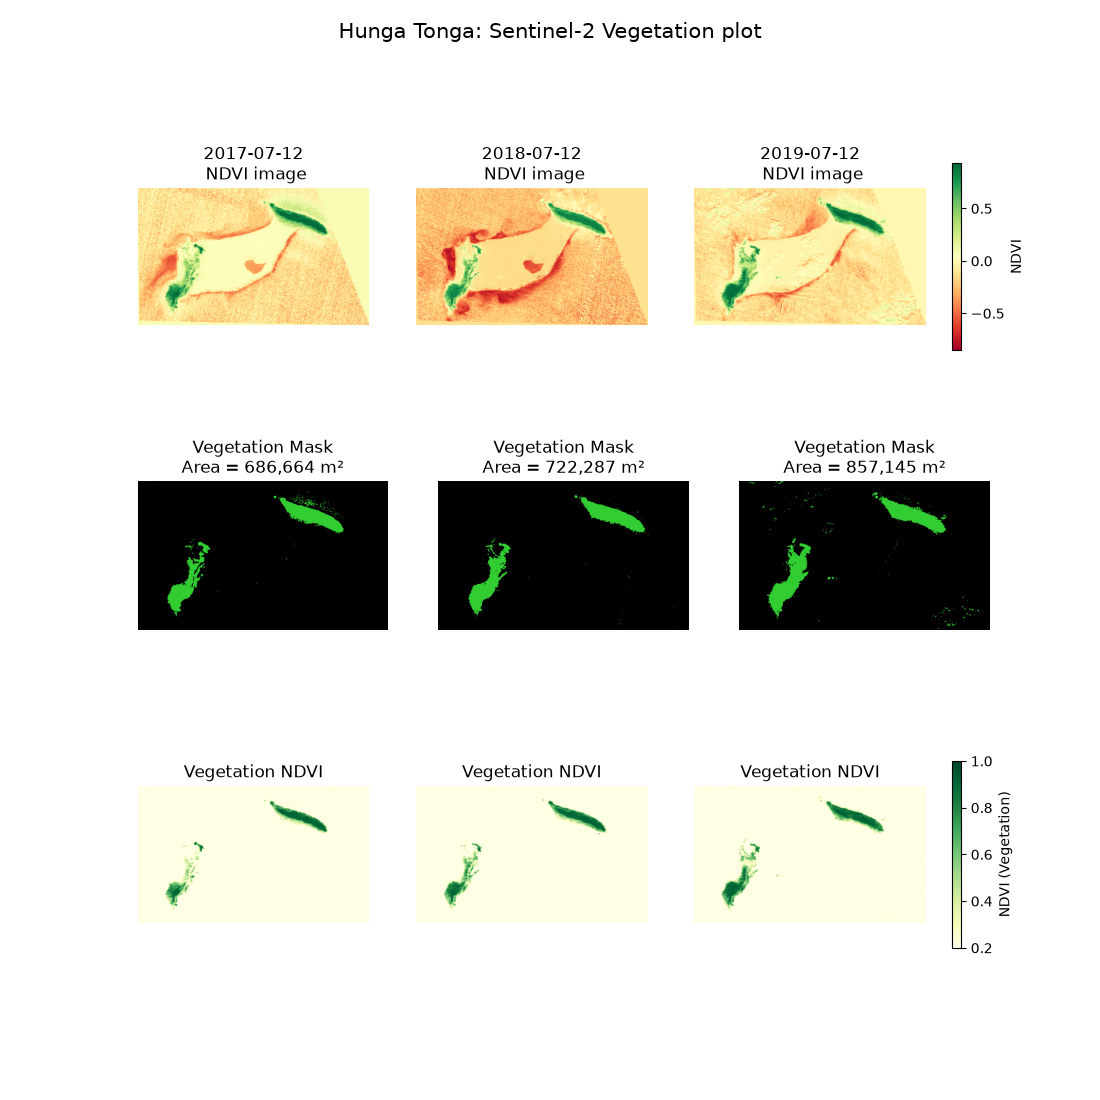

In [13]:
def plot_vegetation_comparison(combined_vegetation, ndvi_threshold=0.2):
    total_images = len(combined_vegetation)
    
    fig, axes = plt.subplots(nrows=3, ncols=total_images, figsize=(11, 11), sharex=True, sharey=True)
    mask_colors = ListedColormap(["black", "limegreen"])

    for i, vegitation_data in enumerate(combined_vegetation):
        ndvi = vegitation_data["ndvi"]
        veg_mask = vegitation_data["veg_mask"]
        date = vegitation_data["date"].replace("S2_", "")
        area = vegitation_data["veg_area_m2"]

        # Row 1 for NDVI image
        ax_ndvi = axes[0, i]
        img_ndvi = ax_ndvi.imshow(ndvi, cmap="RdYlGn")
        ax_ndvi.set_title(f"{date}\n NDVI image")
        ax_ndvi.axis("off")

        # Row 2 for vegetation mask
        ax_mask = axes[1, i]
        ax_mask.imshow(veg_mask, cmap=mask_colors)
        ax_mask.set_title(f"Vegetation Mask\nArea = {area:,.0f} m²")
        ax_mask.axis("off")

        # Row 3 for NDVI vegetation representation 
        ax_veg = axes[2, i]
        # np.where will replace all non vegetation pixels with 0 to hide them
        ndvi_mask = np.where(veg_mask, ndvi, 0) 
        img_veg = ax_veg.imshow(ndvi_mask, cmap="YlGn", vmin=ndvi_threshold, vmax=1)
        ax_veg.set_title("Vegetation NDVI")
        ax_veg.axis("off")

    fig.colorbar(img_ndvi, ax=axes[0, :], shrink=0.75, fraction=0.045, pad=0.03, label="NDVI")
    fig.colorbar(img_veg, ax=axes[2, :],  shrink=0.75, fraction=0.045, pad=0.03, label="NDVI (Vegetation)")

    fig.suptitle("Hunga Tonga: Sentinel-2 Vegetation plot", fontsize=15)
    plt.show() 

plt.close('all')
plot_vegetation_comparison(combined_vegetation)

###  Comparing spectral index

In [14]:
def calculate_ndi(band_a, band_b):
    """
    Calculates Normalized Difference Index: (Band A - Band B) / (Band A + Band B)
    """
    a = band_a
    b = band_b
    
    denominator = a + b
    denominator[denominator == 0] = 0.0001
    
    ndi = (a - b) / denominator
    return ndi

In [16]:
folder = folders_2017[0]
reference_ndvi_file = list(folder.glob("*_NDVI.tiff"))[0]

with rasterio.open(reference_ndvi_file) as src:
    data = src.read(1)
    print(f"Total color bands: {src.count}")

Total color bands: 3


In [17]:
def get_spectral_data(folders):
    """
    Loads bands for each folder, calculates NDVI, NDWI, and Moisture Index, and load the given pipeline files for comparison
    """
    my_spectral_data = []
    
    for folder in folders:
        b03_file = list(folder.glob("*_B03_Raw.tiff"))[0]
        b04_file = list(folder.glob("*_B04_Raw.tiff"))[0]
        b08_file = list(folder.glob("*_B08_Raw.tiff"))[0]
        b8a_file = list(folder.glob("*_B8A_Raw.tiff"))[0]
        b11_file = list(folder.glob("*_B11_Raw.tiff"))[0]
        
        # raw bands
        with rasterio.open(b03_file) as src: 
            b03 = src.read(1)
        with rasterio.open(b04_file) as src: 
            b04 = src.read(1)
        with rasterio.open(b08_file) as src: 
            b08 = src.read(1)
        with rasterio.open(b8a_file) as src: 
            b8a = src.read(1)
        with rasterio.open(b11_file) as src: 
            b11 = src.read(1)
        
        # Calculating spectral index
        my_ndvi = calculate_ndi(b08, b04)
        my_ndwi = calculate_ndi(b03, b08)
        my_moisture = calculate_ndi(b8a, b11)
        
        # Loading given pipeline files for comparison
        pipeline_ndvi_file = list(folder.glob("*_NDVI.tiff"))[0]
        pipeline_ndwi_file = list(folder.glob("*_NDWI.tiff"))[0]
        pipeline_moisture_file = list(folder.glob("*_Moisture_index.tiff"))[0]
        
        with rasterio.open(pipeline_ndvi_file) as src: 
            given_ndvi = src.read(1)
        with rasterio.open(pipeline_ndwi_file) as src: 
            given_ndwi = src.read(1)
        with rasterio.open(pipeline_moisture_file) as src: 
            given_moisture = src.read(1)
        
        my_spectral_data.append({
            "folder_name": folder.name,
            "my_ndvi": my_ndvi,
            "given_ndvi": given_ndvi,
            "my_ndwi": my_ndwi,
            "given_ndwi": given_ndwi,
            "my_moisture": my_moisture,
            "given_moisture": given_moisture
        })
        
    return my_spectral_data

spectral_data_2017 = get_spectral_data(folders_2017)
spectral_data_2018 = get_spectral_data(folders_2018)
spectral_data_2019 = get_spectral_data(folders_2019)

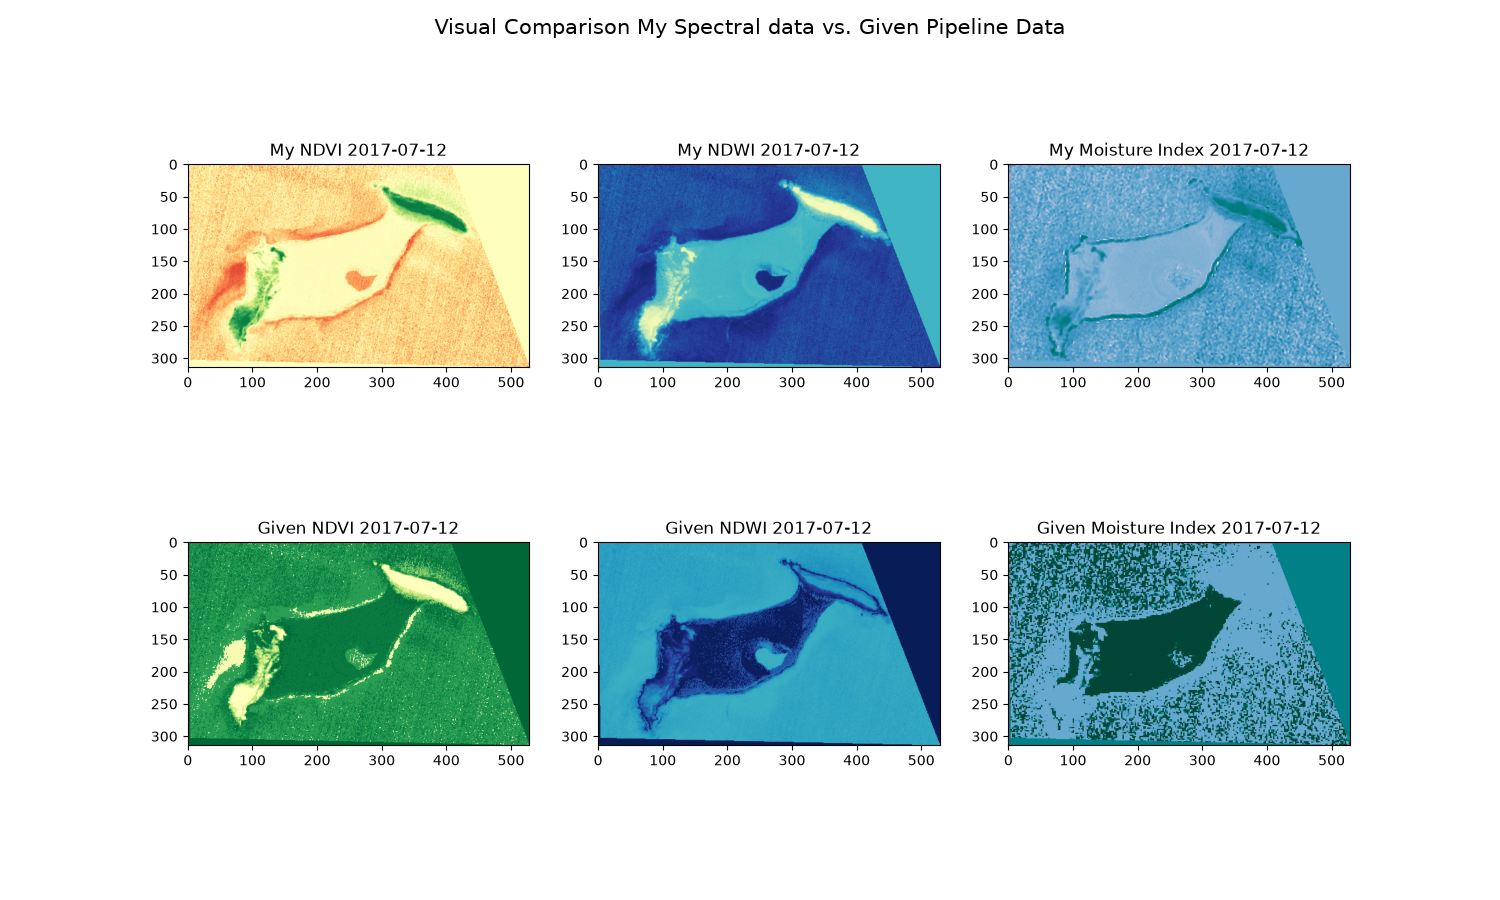

In [18]:
plot_data_2017 = spectral_data_2017[0]
date_title = plot_data_2017["folder_name"].replace("S2_", "")

plt.close('all')
fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(15, 9))

# Row 1 My spectral data
axes[0, 0].imshow(plot_data_2017["my_ndvi"], cmap="RdYlGn", vmin=-1, vmax=1)
axes[0, 0].set_title(f"My NDVI {date_title}")

axes[0, 1].imshow(plot_data_2017["my_ndwi"], cmap="YlGnBu", vmin=-1, vmax=1)
axes[0, 1].set_title(f"My NDWI {date_title}")

axes[0, 2].imshow(plot_data_2017["my_moisture"], cmap="PuBuGn", vmin=-1, vmax=1)
axes[0, 2].set_title(f"My Moisture Index {date_title}")

# Row 2 given pipeline file
axes[1, 0].imshow(plot_data_2017["given_ndvi"], cmap="RdYlGn", vmin=-1, vmax=1)
axes[1, 0].set_title(f"Given NDVI {date_title}")

axes[1, 1].imshow(plot_data_2017["given_ndwi"], cmap="YlGnBu", vmin=-1, vmax=1)
axes[1, 1].set_title(f"Given NDWI {date_title}")

axes[1, 2].imshow(plot_data_2017["given_moisture"], cmap="PuBuGn", vmin=-1, vmax=1)
axes[1, 2].set_title(f"Given Moisture Index {date_title}")

fig.suptitle("Visual Comparison My Spectral data vs. Given Pipeline Data", fontsize=15)
plt.show()

In [19]:
def calculate_error(my_image, pipeline_image):
    """
    Calculate Mean Absolute Error (MAE) and Root Mean Square Error (RMSE)between generated index and pipeline provided index.
    """
    
    diff = pipeline_image - my_image
    mae = np.mean(np.abs(diff))
    rmse = np.sqrt(np.mean(diff ** 2))
    
    return mae, rmse

In [20]:
print("Quantitative Difference Analysis (NDVI)")
print("-"*25)
for data in spectral_data_2017:
    date_name = data["folder_name"]
    mae, rmse = calculate_error(data["my_ndvi"], data["given_ndvi"])
    
    print(f"Date: {date_name}")
    print(f"Mean Absolute Error (MAE) : {mae:.4f}")
    print(f"Root Mean Square Error (RMSE): {rmse:.4f}")
print("-"*25)
for data in spectral_data_2018:
    date_name = data["folder_name"]
    mae, rmse = calculate_error(data["my_ndvi"], data["given_ndvi"])
    
    print(f"Date: {date_name}")
    print(f"Mean Absolute Error (MAE) : {mae:.4f}")
    print(f"Root Mean Square Error (RMSE): {rmse:.4f}")
print("-"*25)
for data in spectral_data_2019:
    date_name = data["folder_name"]
    mae, rmse = calculate_error(data["my_ndvi"], data["given_ndvi"])
    
    print(f"Date: {date_name}")
    print(f"Mean Absolute Error (MAE) : {mae:.4f}")
    print(f"Root Mean Square Error (RMSE): {rmse:.4f}")
print("-"*25)

Quantitative Difference Analysis (NDVI)
-------------------------
Date: S2_2017-07-12
Mean Absolute Error (MAE) : 0.9683
Root Mean Square Error (RMSE): 0.9831
-------------------------
Date: S2_2018-07-12
Mean Absolute Error (MAE) : 0.9520
Root Mean Square Error (RMSE): 0.9641
-------------------------
Date: S2_2019-07-12
Mean Absolute Error (MAE) : 0.9435
Root Mean Square Error (RMSE): 0.9570
-------------------------


#### Interpretation:
MAE and RMSE nearly $0$ proves that Calculated spectral image data matches the Sentinel-2 processing pipeline. The higher MAE and RMSE values may be due to the difference between the two datasets. The pipeline files provided are pre-rendered 3-channel images for range ($0.0$ to $1.0$), while my calcualted data images are for the range ($-1.0$ to $1.0$). I have used google gemini to solve this error but it gave same results everytime.

#### AI Useage:
Same as part A, To get good techniques on  quantitative analysis,I have used Google Gemini for initial research. Also, I have used this to identify some errors along the steps. </br>
Prompt for quantitative analysis: </br>
I need to compare my spectral index images against the already given the Sentinel-2 pipeline image. I need to Identify differences and explain them using quantitative metrics. I have to comapre the pixel values of these two images, what are some standard techniques or formulas I can use to measure the difference between them? Follow the guidelines of AI useage given in this webstie: https://aiassessmentscale.com/
</br> </br>
With this prompt it suggested to comapre using Mean Mean Absolute Error (MAE) and Root Mean Square Error (RMSE), which are like this:</br></br>
MAE (Mean Absolute Error): $\frac{1}{N} \sum \vert{}\text{Custom} - \text{Pipeline}\vert{}$</br></br>RMSE (Root Mean Square Error): $\sqrt{\frac{1}{N} \sum (\text{Custom} - \text{Pipeline})^2}$